# Abstract Text Classification Project
Classifying research-paper abstracts into **Science**, **Business** and **Social Science** using classical ML models (Logistic Regression, Decision Tree, Naive Bayes, kNN, Linear SVC, Random Forest) with Bag-of-Words and TF-IDF features.

**Pipeline:** 
- dataset collection 
- loading & cleaning
- text preprocessing
- train/test split
- model training (GridSearchCV)
- evaluation
- interpretation
- saving models


# 1. Dataset Preparation
The dataset is built from the **OpenAlex API**. Abstracts are sampled for each class from several research fields and several years, so the final dataset is balanced across classes.

### 1.1 Imports and configuration
Imports the libraries for API calls and data handling, then sets the collection parameters: total size (20,000 abstracts), publication years (2016–2025), abstract length limits (50–500 words), minimum topic confidence (0.9), and random seed.

In [3]:
import re
import math
import time
import random
from collections import Counter
from pathlib import Path

import requests
import pandas as pd

API_URL = "https://api.openalex.org/works"
MAILTO = "vkce04@gmail.com"                    # optional: your email for OpenAlex's polite pool
TARGET_TOTAL = 20000           # total abstracts, split evenly across classes
YEARS = list(range(2016, 2026))
MIN_WORDS, MAX_WORDS = 50, 500
MIN_TOPIC_SCORE = 0.9          # keep only confidently classified works
SEED = 42
SAMPLE_N = 200                 # max page size when using OpenAlex sampling
MAX_BATCHES = 12               # random batches per (field, year) in main pass
MAX_TOPUP_ROUNDS = 40          # safety cap for the top-up phase
REVIEW_PER_CLASS = 30          # rows exported for manual label checking

### 1.2 Class definitions and per-class targets
Maps each class label to the OpenAlex research fields that belong to it, and splits the 20,000 target as evenly as possible across the three classes (6667 / 6667 / 6666).

In [5]:
# Class: {OpenAlex field id: field name}
CLASS_FIELDS = {
    "Science": {
        "11": "Agricultural and Biological Sciences",
        "13": "Biochemistry, Genetics and Molecular Biology",
        "16": "Chemistry",
        "19": "Earth and Planetary Sciences",
        "31": "Physics and Astronomy",
        "23": "Environmental Science",
        "24": "Immunology and Microbiology",
        "25": "Materials Science",
        "26": "Mathematics",
        "28": "Neuroscience",
    },
    "Business": {
        "14": "Business, Management and Accounting",
        "20": "Economics, Econometrics and Finance",
        "18": "Decision Sciences",
    },
    "Social Science": {
        "33": "Social Sciences",
        "32": "Psychology",
        "12": "Arts and Humanities",
    },
}

n_classes = len(CLASS_FIELDS)
base, rem = divmod(TARGET_TOTAL, n_classes)
TARGETS = {label: base + (1 if i < rem else 0)
           for i, label in enumerate(CLASS_FIELDS)}

SELECT = ("id,doi,title,publication_year,abstract_inverted_index,"
          "primary_location,primary_topic,language")

### 1.3 HTTP session
Created a reusable `requests` session with a custom User-Agent, so connections are reused across the many API calls.

In [6]:
session = requests.Session()
session.headers.update({"User-Agent": "abstract-classification-project (Colab)"})

### 1.4 Text helper functions
OpenAlex returns abstracts as an *inverted index* (word → positions). `reconstruct_abstract` rebuilds the plain text, and `clean_abstract` removes HTML tags, a leading "Abstract" label and copyright boilerplate.

In [7]:
def reconstruct_abstract(inverted_index):
    """Convert OpenAlex's word->positions index into plain text."""
    if not inverted_index:
        return ""
    words = {}
    for word, positions in inverted_index.items():
        for pos in positions:
            words[int(pos)] = word
    return " ".join(words[p] for p in sorted(words))


def clean_abstract(text):
    """Strip HTML tags, leading 'Abstract' label, and copyright boilerplate."""
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"^\s*abstract[:.\s]+", "", text, flags=re.IGNORECASE)
    text = re.sub(r"(©|\(c\)|copyright)[^.]*\.?", " ", text, flags=re.IGNORECASE)
    text = re.sub(r"all rights reserved\.?", " ", text, flags=re.IGNORECASE)
    return re.sub(r"\s+", " ", text).strip()

### 1.5 API request function
`fetch_batch` pulls a random sample of works for one field and year. It retries with exponential backoff on rate-limit (429) and server errors.

In [8]:
def fetch_batch(field_id, year, seed):
    """Random sample of works for one field and year, with retry/backoff."""
    params = {
        "filter": (
            f"primary_topic.field.id:fields/{field_id},"
            f"publication_year:{year},type:article,language:en,has_abstract:true"
        ),
        "sample": SAMPLE_N,
        "seed": seed,
        "per_page": SAMPLE_N,
        "select": SELECT,
    }
    if MAILTO.strip():
        params["mailto"] = MAILTO.strip()

    for attempt in range(4):
        try:
            r = session.get(API_URL, params=params, timeout=30)
            if r.status_code == 429 or r.status_code >= 500:
                time.sleep(2 ** attempt)
                continue
            r.raise_for_status()
            return r.json().get("results", [])
        except requests.RequestException as e:
            print(f"  request error (field {field_id}, {year}): {e}")
            time.sleep(2 ** attempt)
    return []

### 1.6 Collection helpers
`try_add` applies the quality filters (topic confidence, no duplicate IDs or abstracts, word-count limits) and stores a record if it passes. `collect` repeatedly fetches batches until the quota for a (field, year) is met.

In [9]:
seen_ids, seen_abstracts = set(), set()
records = []
class_counts = Counter()


def try_add(work, label, field_name):
    """Apply quality filters; store the record if it passes."""
    topic = work.get("primary_topic") or {}
    if (topic.get("score") or 0) < MIN_TOPIC_SCORE:
        return False

    work_id = work.get("id")
    if not work_id or work_id in seen_ids:
        return False

    abstract = clean_abstract(reconstruct_abstract(work.get("abstract_inverted_index")))
    n_words = len(abstract.split())
    if not (MIN_WORDS <= n_words <= MAX_WORDS):
        return False

    key = re.sub(r"\W+", " ", abstract.lower()).strip()
    if key in seen_abstracts:
        return False

    seen_ids.add(work_id)
    seen_abstracts.add(key)
    source = (work.get("primary_location") or {}).get("source") or {}
    records.append({
        "title": work.get("title") or "",
        "Abstract": abstract,
        "label": label,
        "field": field_name,
        "subfield": (topic.get("subfield") or {}).get("display_name", ""),
        "topic": topic.get("display_name", ""),
        "topic_score": topic.get("score"),
        "year": work.get("publication_year"),
        "journal": source.get("display_name") or "",
        "doi": work.get("doi") or "",
        "openalex_id": work_id,
        "word_count": n_words,
    })
    class_counts[label] += 1
    return True


def collect(label, field_id, field_name, year, quota, seed_offset=0,
            max_batches=MAX_BATCHES):
    """Collect up to `quota` new abstracts for one (field, year)."""
    got = 0
    for batch in range(max_batches):
        works = fetch_batch(field_id, year, seed=SEED + seed_offset + batch)
        if seed_offset == 0 and batch == 0 and not works:
            print(f"  WARNING: no results for field {field_id} ({field_name}), "
                  f"{year}. Check the field ID.")
        for w in works:
            if got >= quota:
                break
            if try_add(w, label, field_name):
                got += 1
        if got >= quota:
            break
        time.sleep(0.2)
    return got

### 1.7 Main collection pass
Loops over every class, field and year, collecting an even quota for each, so the data is spread across fields and time.

In [10]:
for label, fields in CLASS_FIELDS.items():
    per_field = math.ceil(TARGETS[label] / len(fields))
    per_year = math.ceil(per_field / len(YEARS))
    print(f"\nCollecting {label} ({len(fields)} fields, ~{per_year} per field-year)...")

    for field_id, field_name in fields.items():
        field_total = sum(
            collect(label, field_id, field_name, year, per_year) for year in YEARS
        )
        print(f"  {field_name}: {field_total}")


  Agricultural and Biological Sciences: 670
  Biochemistry, Genetics and Molecular Biology: 670
  Chemistry: 670
  Earth and Planetary Sciences: 670
  Physics and Astronomy: 670
  Environmental Science: 670
  Immunology and Microbiology: 670
  Materials Science: 670
  Mathematics: 670
  Neuroscience: 670

  Business, Management and Accounting: 2230
  Economics, Econometrics and Finance: 2230
  Decision Sciences: 2230

  Social Sciences: 2230
  Psychology: 2230
  Arts and Humanities: 2230


### 1.8 Top-up pass
If any class is still short of its target after the main pass, extra random batches are fetched until the target is reached (capped by `MAX_TOPUP_ROUNDS`).

In [11]:
rng = random.Random(SEED)
for label, fields in CLASS_FIELDS.items():
    rounds = 0
    while class_counts[label] < TARGETS[label] and rounds < MAX_TOPUP_ROUNDS:
        rounds += 1
        print(f"  Top-up {label} round {rounds}: "
              f"need {TARGETS[label] - class_counts[label]} more")
        combos = [(fid, fname, y) for fid, fname in fields.items() for y in YEARS]
        rng.shuffle(combos)
        for fid, fname, y in combos:
            missing = TARGETS[label] - class_counts[label]
            if missing <= 0:
                break
            collect(label, fid, fname, y, quota=min(50, missing),
                    seed_offset=1000 * rounds, max_batches=2)

df = pd.DataFrame(records)
if df.empty:
    raise RuntimeError("No abstracts collected. Check connection and field IDs.")

### 1.9 Balance classes and shuffle
Builds the DataFrame, trims classes to exact sizes (or to the smallest class if one fell short), and shuffles the rows.

In [12]:
available = df["label"].value_counts()
short = [l for l in TARGETS if available.get(l, 0) < TARGETS[l]]
if short:
    # a class fell short: trim every class to the smallest so labels stay balanced
    n_min = int(available.min())
    print(f"WARNING: {short} below target; trimming all classes to {n_min}.")
    sizes = {l: n_min for l in TARGETS}
else:
    sizes = TARGETS

df = (
    pd.concat([g.sample(n=sizes[l], random_state=SEED)
               for l, g in df.groupby("label")])
      .sample(frac=1, random_state=SEED)       # shuffle
      .reset_index(drop=True)
)
n_per_class = int(df["label"].value_counts().min())   # used by the review sample

### 1.10 Save dataset and quality report
Saves the dataset to `abstracts.csv` and prints a summary: counts per label and field, abstract length statistics, and papers per year.

In [13]:
#Saving the dataset
output_file = Path("abstracts.csv")
df.to_csv(output_file, index=False)

# Dataset Info
print("\nDataset saved:", output_file.resolve())
print("\nCounts per label:\n", df["label"].value_counts())
print("\nCounts per field:\n", df.groupby(["label", "field"]).size())
print("\nAbstract length (words) by label:")
print(df.groupby("label")["word_count"].describe()[["mean", "min", "max"]].round(1))
print("\nPapers per year:\n", df["year"].value_counts().sort_index())
print("\nTotal abstracts:", len(df))
display(df[["title", "label", "field", "year"]].head())


Dataset saved: C:\Users\lenovo\Downloads\abstractapi\abstracts.csv

Counts per label:
 label
Science           6667
Business          6667
Social Science    6666
Name: count, dtype: int64

Counts per field:
 label           field                                       
Business        Business, Management and Accounting             2225
                Decision Sciences                               2220
                Economics, Econometrics and Finance             2222
Science         Agricultural and Biological Sciences             667
                Biochemistry, Genetics and Molecular Biology     667
                Chemistry                                        669
                Earth and Planetary Sciences                     668
                Environmental Science                            667
                Immunology and Microbiology                      667
                Materials Science                                664
                Mathematics             

,title,label,field,year
0,Moleküler demet epitaksi ile büyütülen Ga0.965...,Science,Physics and Astronomy,2021
1,Χρηματοδότηση των νοικοκυριών στην Ελλάδα,Business,"Economics, Econometrics and Finance",2023
2,Prevalence and Characteristics of Salmonella s...,Science,Agricultural and Biological Sciences,2022
3,Preferential trade agreements with labour prov...,Business,"Economics, Econometrics and Finance",2024
4,Knowledge and perception of mental disorders a...,Social Science,Psychology,2019


# 2. Data Loading and Cleaning

### 2.1 Load the dataset
load the saved `abstracts.csv` back into a DataFrame. (The `Dataset` path variable and `os.listdir` line are leftovers and not used.)

In [9]:
import os
import pandas as pd

Dataset = ''

# List all files in the directory to find the CSVs
#files = os.listdir(Dataset)

# load dataset
dataset = pd.read_csv('abstracts.csv')

### 2.2 Inspect the raw data
Checks column names, data types and non-null counts.

In [10]:
print(dataset.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   title        20000 non-null  object 
 1   Abstract     20000 non-null  object 
 2   label        20000 non-null  object 
 3   field        20000 non-null  object 
 4   subfield     20000 non-null  object 
 5   topic        20000 non-null  object 
 6   topic_score  20000 non-null  float64
 7   year         20000 non-null  int64  
 8   journal      19492 non-null  object 
 9   doi          17585 non-null  object 
 10  openalex_id  20000 non-null  object 
 11  word_count   20000 non-null  int64  
dtypes: float64(1), int64(2), object(9)
memory usage: 1.8+ MB
None


### 2.3 Drop unneeded columns and empty abstracts
Keeps only the `Abstract` text and `label`. The metadata columns are dropped, and rows with missing or blank abstracts are removed.

In [11]:
# Drop specified columns
columns_to_drop = ['title', 'field', 'subfield','topic','topic_score','year','journal','doi','openalex_id','word_count']
# Use errors='ignore' in case some columns are already dropped or not present
df = dataset.drop(columns=columns_to_drop, errors='ignore')

#Drop entries with no abstracts (NaN, null, or empty string)
df = df.dropna(subset=['Abstract'])
df = df[df['Abstract'].astype(str).str.strip() != '']

# Display information and the first few rows of the merged dataset
print(df.info())
print(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Abstract  20000 non-null  object
 1   label     20000 non-null  object
dtypes: object(2)
memory usage: 312.6+ KB
None
                                            Abstract           label
0  In this paper we prove the equivalence among (...         Science
1  This research paper delves into the intricate ...        Business
2  Abstract—ThePleurophyllumclade is one of two m...         Science
3  Tax evasion and avoidance have remained fundam...        Business
4  BACKGROUND: Suicide is the second leading caus...  Social Science


### 2.4 Remove duplicate abstracts
Drops every copy of any abstract that appears more than once (`keep=False`) so the same text can't land in both train and test sets, then re-checks the class balance.

In [12]:
# Check how many duplicate abstracts exist
num_duplicates = df.duplicated(subset=['Abstract'], keep=False).sum()
print(f"Number of duplicate abstracts found (including all copies): {num_duplicates}")

# Drop all occurrences of duplicates entirely
df = df.drop_duplicates(subset=['Abstract'], keep=False)

# Check the new shape of the dataset
print("New dataset shape:", df.shape)
print(df['label'].value_counts())

Number of duplicate abstracts found (including all copies): 0
New dataset shape: (20000, 2)
label
Science           6667
Business          6667
Social Science    6666
Name: count, dtype: int64


# 3. Text Preprocessing
The raw abstracts are converted into clean, normalised text that suits the vectorizers.

### 3.1 Imports and NLTK resources
Imports NLTK tools for tokenising, POS tagging, stopwords and lemmatisation, and downloads the required resources (once per session).

In [13]:
import re
import unicodedata
import nltk

from functools import lru_cache
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer

# Download resources once per Colab session
# (requires NLTK >= 3.8.2; on older versions use "averaged_perceptron_tagger" and "punkt")
for resource in [
    "averaged_perceptron_tagger_eng",
    "stopwords",
    "wordnet",
    "punkt",
    "punkt_tab",
]:
    nltk.download(resource)
nltk.download('averaged_perceptron_tagger')
LEMMATIZER = WordNetLemmatizer()

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package a

### 3.2 Stopword list
Uses NLTK's English stopwords but **keeps negation words** (`no`, `not`, `never`, `cannot`, ...) because they can change the meaning of a sentence.

In [14]:
# Negation words are removed from the stopword list so they are preserved,
# because they can change the meaning of a sentence.
NEGATION_WORDS = {
    "no", "nor", "not", "never", "neither",
    "cannot", "without",
}

STOP_WORDS = set(stopwords.words("english")) - NEGATION_WORDS

### 3.3 Contraction and character maps
Defines the dictionary and regex patterns used to expand contractions (`can't` → `cannot`), plus a map that converts curly quotes and dashes to plain ASCII.

In [15]:
CONTRACTIONS_DICT = {
    "can't": "cannot",
    "won't": "will not",
    "don't": "do not",
    "doesn't": "does not",
    "didn't": "did not",
    "isn't": "is not",
    "aren't": "are not",
    "wasn't": "was not",
    "weren't": "were not",
    "haven't": "have not",
    "hasn't": "has not",
    "hadn't": "had not",
    "shouldn't": "should not",
    "couldn't": "could not",
    "wouldn't": "would not",
    "shan't": "shall not",
    "ain't": "is not",
}

CONTRACTION_PATTERN = re.compile(
    r"\b(" + "|".join(
        re.escape(k) for k in sorted(CONTRACTIONS_DICT, key=len, reverse=True)
    ) + r")\b",
    flags=re.IGNORECASE,
)

# Generic fallback for contractions not in the dictionary (mustn't, needn't, ...)
GENERIC_NT_PATTERN = re.compile(r"\b(\w+)n't\b", flags=re.IGNORECASE)

# Curly quotes / dashes mapped to ASCII BEFORE the ascii-ignore step
CHAR_MAP = str.maketrans({
    "\u2019": "'",   # right single quote
    "\u2018": "'",   # left single quote
    "\u02bc": "'",   # modifier letter apostrophe
    "\u201c": '"',   # left double quote
    "\u201d": '"',   # right double quote
    "\u2013": "-",   # en dash
    "\u2014": "-",   # em dash
})

### 3.4 Cleaning helpers
`expand_contractions` expands contractions. `clean_unicode_and_noise` normalises unicode to ASCII and removes emails and URLs.

In [16]:
def expand_contractions(text):
    def replace(match):
        return CONTRACTIONS_DICT[match.group(0).lower()]

    text = CONTRACTION_PATTERN.sub(replace, text)
    return GENERIC_NT_PATTERN.sub(r"\1 not", text)


def clean_unicode_and_noise(text):
    text = text.translate(CHAR_MAP)
    text = unicodedata.normalize("NFKD", text)
    text = text.encode("ascii", "ignore").decode("ascii")
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    return text

### 3.5 Lemmatisation helpers
`get_wordnet_pos` maps NLTK POS tags to WordNet tags so the lemmatiser picks the right word form. `cached_lemma` caches lemma lookups with `lru_cache` for speed.

In [17]:
def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("N"):
        return wordnet.NOUN
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN


@lru_cache(maxsize=100_000)
def cached_lemma(word, pos):
    return LEMMATIZER.lemmatize(word, pos=pos)

### 3.6 Token cleaning
`_clean_tagged_tokens` lowercases after POS tagging, splits hyphenated tokens, removes stopwords and single letters (numbers are kept), and lemmatises each word.

In [18]:
def _clean_tagged_tokens(pos_tags):
    """Turn (token, tag) pairs into a cleaned, lemmatized string."""
    cleaned_words = []

    for word, tag in pos_tags:
        wn_pos = get_wordnet_pos(tag)

        # Lowercase only after tagging; split hyphenated/decimal tokens
        # into alphanumeric pieces (state-of-the-art -> state, of, the, art).
        for clean_word in re.findall(r"[a-z0-9]+", word.lower()):
            if clean_word in STOP_WORDS:
                continue

            # Keep numbers; drop single-letter noise.
            if len(clean_word) == 1 and not clean_word.isdigit():
                continue

            cleaned_words.append(cached_lemma(clean_word, wn_pos))

    return " ".join(cleaned_words)

### 3.7 Main preprocessing functions
`preprocess_text` runs the full pipeline on one abstract: clean, tokenise, POS tag, lemmatise. `preprocess_corpus` is a faster batch version using `pos_tag_sents`.

In [19]:
def _prepare(text):
    """Clean + expand contractions, but keep original casing for POS tagging."""
    text = clean_unicode_and_noise(text)
    return expand_contractions(text)


def preprocess_text(text):
    if not isinstance(text, str) or not text.strip():
        return ""

    tokens = word_tokenize(_prepare(text))
    pos_tags = nltk.pos_tag(tokens)
    return _clean_tagged_tokens(pos_tags)


def preprocess_corpus(texts):
    """Faster batch version for large datasets (uses pos_tag_sents)."""
    prepared, valid_idx = [], []
    results = [""] * len(texts)

    for i, t in enumerate(texts):
        if isinstance(t, str) and t.strip():
            prepared.append(word_tokenize(_prepare(t)))
            valid_idx.append(i)

    for i, pos_tags in zip(valid_idx, nltk.pos_tag_sents(prepared)):
        results[i] = _clean_tagged_tokens(pos_tags)

    return results

### 3.8 Apply preprocessing to all abstracts
Runs `preprocess_text` on every abstract (with a progress bar) and stores the result in a new `Cleaned_Abstract` column.

In [20]:
from tqdm.auto import tqdm

# Register tqdm with pandas
tqdm.pandas(desc="Preprocessing abstracts")

print("text preprocessing...")
df['Cleaned_Abstract'] = df['Abstract'].progress_apply(preprocess_text)

# Preview the cleaned data
print("Preprocessing completed!")
print(df[['Abstract', 'Cleaned_Abstract', 'label']].head())

text preprocessing...


Preprocessing abstracts:   0%|          | 0/20000 [00:00<?, ?it/s]

Preprocessing completed!
                                            Abstract  \
0  In this paper we prove the equivalence among (...   
1  This research paper delves into the intricate ...   
2  Abstract—ThePleurophyllumclade is one of two m...   
3  Tax evasion and avoidance have remained fundam...   
4  BACKGROUND: Suicide is the second leading caus...   

                                    Cleaned_Abstract           label  
0  paper prove equivalence among weakly couple wo...         Science  
1  research paper delve intricate dynamic carbon ...        Business  
2  abstract thepleurophyllumclade one two main cl...         Science  
3  tax evasion avoidance remain fundamental reaso...        Business  
4  background suicide second leading cause death ...  Social Science  


# 4. Train/Test Split

### 4.1 Imports
Imports the libraries for modelling, evaluation and plotting.

In [21]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    precision_recall_fscore_support,
)
from tempfile import mkdtemp
cache_dir = mkdtemp()

### 4.2 Stratified train/test split
Creates an `outputs/` folder for saved results, then splits the data 80/20. `stratify` keeps class proportions the same in both sets.

In [22]:
os.makedirs("outputs", exist_ok=True)

X_train_raw, X_test_raw, Y_train, Y_test = train_test_split(
    df["Cleaned_Abstract"],
    df["label"],
    test_size=0.2,
    random_state=42,
    stratify=df["label"],
)

labels = sorted(Y_train.unique())
print(f"Train: {len(X_train_raw)} | Test: {len(X_test_raw)} | Classes: {len(labels)}")

Train: 16000 | Test: 4000 | Classes: 3


# 5. Model Training with Hyperparameter Search

### 5.1 Model grids
Defines the six classifiers with the hyperparameter grid to search for each: Logistic Regression, Decision Tree, Multinomial NB, kNN, Linear SVC and Random Forest. A temporary directory is created to cache pipeline steps.

In [23]:
#Design and training Multiple model
from tempfile import mkdtemp
cache_dir = mkdtemp()

model_grids = {
    "Logistic Regression": {
        "model": LogisticRegression(max_iter=2000, random_state=42),
        "params": {"classifier__C": [0.01, 0.1, 1.0, 10.0, 50.0]},
    },
    "Decision Tree": {
        "model": DecisionTreeClassifier(random_state=42),
        "params": {
            "classifier__max_depth": [5, 10, 20, 30, 50],
            "classifier__min_samples_split": [2, 5, 10],
        },
    },
    "Multinomial NB": {
        "model": MultinomialNB(),
        "params": {"classifier__alpha": [0.1, 0.5, 1.0]},
    },
    "KNN": {
        "model": KNeighborsClassifier(algorithm="brute", n_jobs=-1),
        "params": {
            "classifier__n_neighbors": [3, 5, 7],
            "classifier__metric": ["cosine", "euclidean"],
        },
    },
    "Linear SVC": {
        "model": LinearSVC(max_iter=2500, random_state=42),
        "params": {"classifier__C": [0.1, 1.0, 10.0]},
    },
    "Random Forest": {
        "model": RandomForestClassifier(random_state=42, n_jobs=-1),
        "params": {
            "classifier__n_estimators": [50, 100],
            "classifier__max_depth": [None, 30, 50],
        },
    },
}

### 5.2 Vectorizers
Two text representations are compared: **Bag of Words** (word counts, top 5000 features) and **TF-IDF** (unigrams + bigrams, sublinear TF, 5000 features).

In [24]:
vectorizers = {
    "Bag of Words": CountVectorizer(max_features=5000),
    "TF-IDF": TfidfVectorizer(
        ngram_range=(1, 2), max_features=5000, sublinear_tf=True, min_df=3, norm='l2'
    ),
}

### 5.3 Containers for results
Dictionaries that hold each fitted best pipeline and its cross-validation scores, best parameters and fit time.

In [25]:
best_models = {}      # fitted best pipelines, used for interpretation later
cv_info = {}          # CV scores, best params, timing

### 5.4 Run GridSearchCV for every vectorizer and model
For each of the 12 combinations, builds a `Pipeline` (vectorizer + classifier) and runs 3-fold `GridSearchCV` scored on macro F1. The best pipeline and its metrics are stored. **This is the slowest cell in the notebook.**

In [26]:
for vec_name, vectorizer in vectorizers.items():
    for model_name, config in model_grids.items():
        combo_key = f"{vec_name} + {model_name}"
        print(f"Running GridSearchCV for: {combo_key}...")

        pipeline = Pipeline([
        ("vectorizer", vectorizer),
        ("classifier", config["model"]),
        ], memory=cache_dir)

        grid = GridSearchCV(
            pipeline,
            param_grid=config["params"],
            cv=3,
            scoring="f1_macro",
            return_train_score=True,
            n_jobs=-1,
        )

        start = time.time()
        grid.fit(X_train_raw, Y_train)
        elapsed = time.time() - start

        i = grid.best_index_
        best_models[combo_key] = grid.best_estimator_
        cv_info[combo_key] = {
            "CV Train Score": grid.cv_results_["mean_train_score"][i],
            "CV Val Score": grid.cv_results_["mean_test_score"][i],
            "Best Params": grid.best_params_,
            "Fit Time (s)": round(elapsed, 1),
        }

print("\nAll models trained.")

Running GridSearchCV for: Bag of Words + Logistic Regression...


C:\Users\lenovo\anaconda3\lib\site-packages\sklearn\pipeline.py:348: UserWarning: Persisting input arguments took 0.74s to run.
If this happens often in your code, it can cause performance problems 
(results will be correct in all cases). 
The reason for this is probably some large input arguments for a wrapped
 function (e.g. large strings).
THIS IS A JOBLIB ISSUE. If you can, kindly provide the joblib's team with an
 example so that they can fix the problem.
  X, fitted_transformer = fit_transform_one_cached(


Running GridSearchCV for: Bag of Words + Decision Tree...
Running GridSearchCV for: Bag of Words + Multinomial NB...
Running GridSearchCV for: Bag of Words + KNN...
Running GridSearchCV for: Bag of Words + Linear SVC...
Running GridSearchCV for: Bag of Words + Random Forest...
Running GridSearchCV for: TF-IDF + Logistic Regression...


C:\Users\lenovo\anaconda3\lib\site-packages\sklearn\pipeline.py:348: UserWarning: Persisting input arguments took 5.21s to run.
If this happens often in your code, it can cause performance problems 
(results will be correct in all cases). 
The reason for this is probably some large input arguments for a wrapped
 function (e.g. large strings).
THIS IS A JOBLIB ISSUE. If you can, kindly provide the joblib's team with an
 example so that they can fix the problem.
  X, fitted_transformer = fit_transform_one_cached(


Running GridSearchCV for: TF-IDF + Decision Tree...
Running GridSearchCV for: TF-IDF + Multinomial NB...
Running GridSearchCV for: TF-IDF + KNN...
Running GridSearchCV for: TF-IDF + Linear SVC...
Running GridSearchCV for: TF-IDF + Random Forest...

All models trained.


# 6. Model Evaluation and Comparison

### 6.1 Evaluate all models on the test set
Predicts on the held-out test set with every best model and computes accuracy and macro precision, recall and F-measure. These are combined with the CV scores in a results table, sorted by test F-measure and saved to CSV. An `Overfit Gap` column (CV train minus CV validation score) is added.

In [27]:
results, preds_store = {}, {}

for combo_key, model in best_models.items():
    preds = model.predict(X_test_raw)
    preds_store[combo_key] = preds

    acc = accuracy_score(Y_test, preds)
    p, r, f1, _ = precision_recall_fscore_support(
        Y_test, preds, average="macro", zero_division=0
    )
    results[combo_key] = {
        "Accuracy": acc,
        "Precision": p,
        "Recall": r,
        "F-measure": f1,
        **cv_info[combo_key],
    }

results_df = pd.DataFrame(results).T
metric_cols = ["CV Train Score", "CV Val Score", "Accuracy", "Precision", "Recall", "F-measure"]
results_df[metric_cols] = results_df[metric_cols].astype(float)
results_df["Overfit Gap"] = results_df["CV Train Score"] - results_df["CV Val Score"]
results_df = results_df.sort_values("F-measure", ascending=False)

print("Evaluation Results (sorted by test F-measure)")
display(results_df[metric_cols + ["Overfit Gap", "Fit Time (s)"]].round(4))
results_df.to_csv("outputs/model_comparison_results.csv")

C:\Users\lenovo\anaconda3\lib\site-packages\sklearn\neighbors\_classification.py:228: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  mode, _ = stats.mode(_y[neigh_ind, k], axis=1)
C:\Users\lenovo\anaconda3\lib\site-packages\sklearn\neighbors\_classification.py:228: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepd

Evaluation Results (sorted by test F-measure)


,CV Train Score,CV Val Score,Accuracy,Precision,Recall,F-measure,Overfit Gap,Fit Time (s)
TF-IDF + Linear SVC,0.9265,0.8860,0.9008,0.9014,0.9008,0.9009,0.0405,16.8
TF-IDF + Logistic Regression,0.9381,0.8885,0.9005,0.9009,0.9005,0.9006,0.0496,91.7
Bag of Words + Logistic Regression,0.9405,0.8801,0.8915,0.8930,0.8915,0.8917,0.0604,50.4
TF-IDF + KNN,0.9155,0.8822,0.8912,0.8915,0.8912,0.8911,0.0332,163.7
TF-IDF + Multinomial NB,0.8870,0.8724,0.8770,0.8774,0.8770,0.8769,0.0146,15.0
Bag of Words + Multinomial NB,0.8926,0.8727,0.8768,0.8770,0.8768,0.8767,0.0198,6.3
Bag of Words + Linear SVC,0.9950,0.8552,0.8728,0.8734,0.8728,0.8729,0.1398,21.0
TF-IDF + Random Forest,0.9969,0.8486,0.8595,0.8595,0.8595,0.8595,0.1483,63.8
Bag of Words + Random Forest,0.9971,0.8488,0.8575,0.8576,0.8575,0.8575,0.1483,41.2
Bag of Words + KNN,0.8719,0.8239,0.8270,0.8339,0.8270,0.8272,0.0479,161.5


### 6.2 Plot: test-set performance
Bar chart comparing accuracy, precision, recall and F-measure for all 12 combinations.

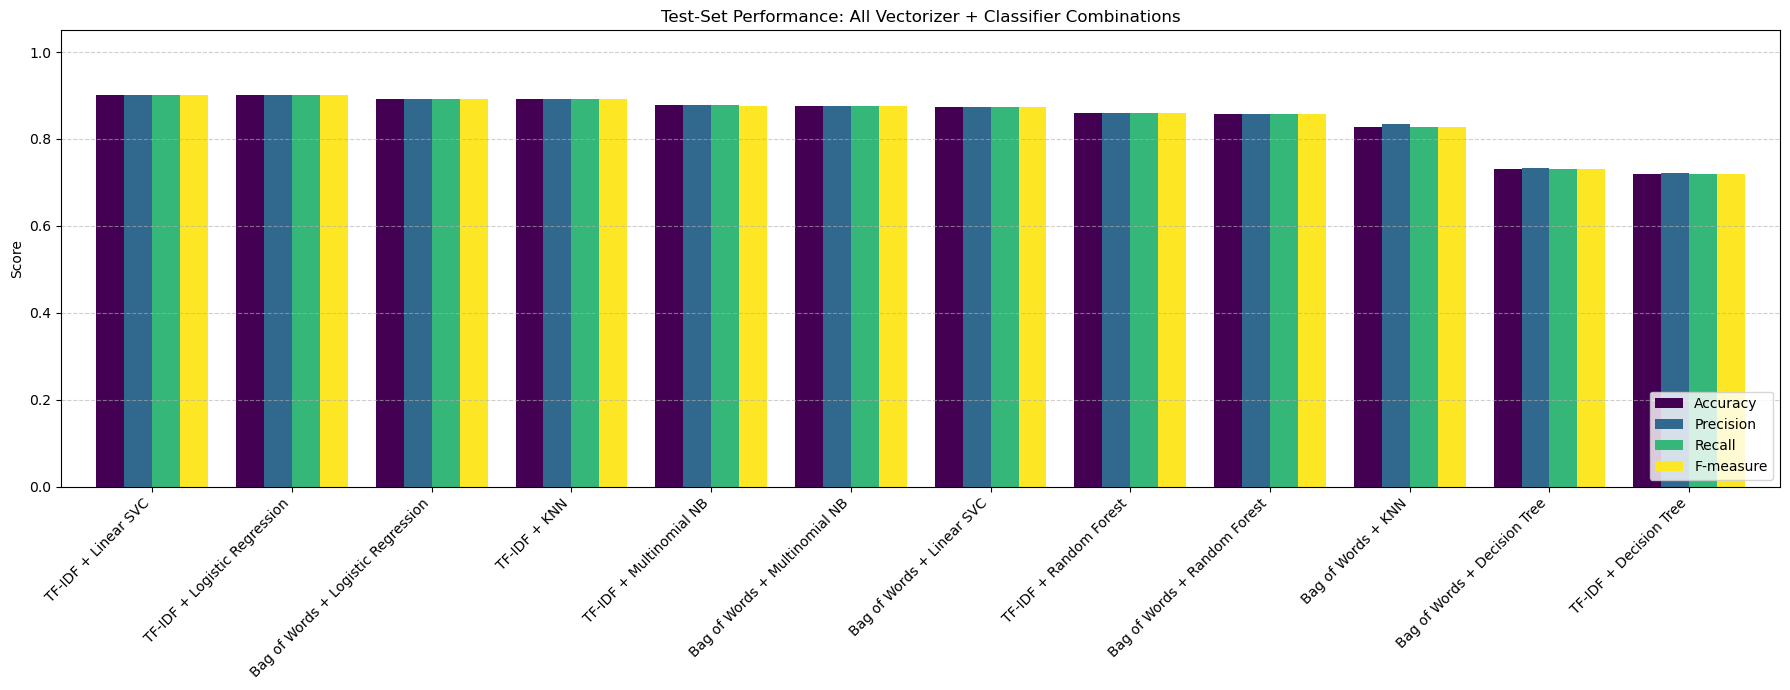

In [28]:
# Plot 1: Accuracy / Precision / Recall / F-measure
plot_df = results_df[["Accuracy", "Precision", "Recall", "F-measure"]]
ax = plot_df.plot(kind="bar", figsize=(18, 7), width=0.8, colormap="viridis")
ax.set_ylabel("Score")
ax.set_title("Test-Set Performance: All Vectorizer + Classifier Combinations")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", linestyle="--", alpha=0.6)
plt.xticks(rotation=45, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("outputs/metrics_comparison.png", dpi=600)
plt.show()

### 6.3 Plot: training vs validation (overfitting check)
Compares mean CV training and validation macro F1 for each model. A large gap between the bars suggests overfitting.

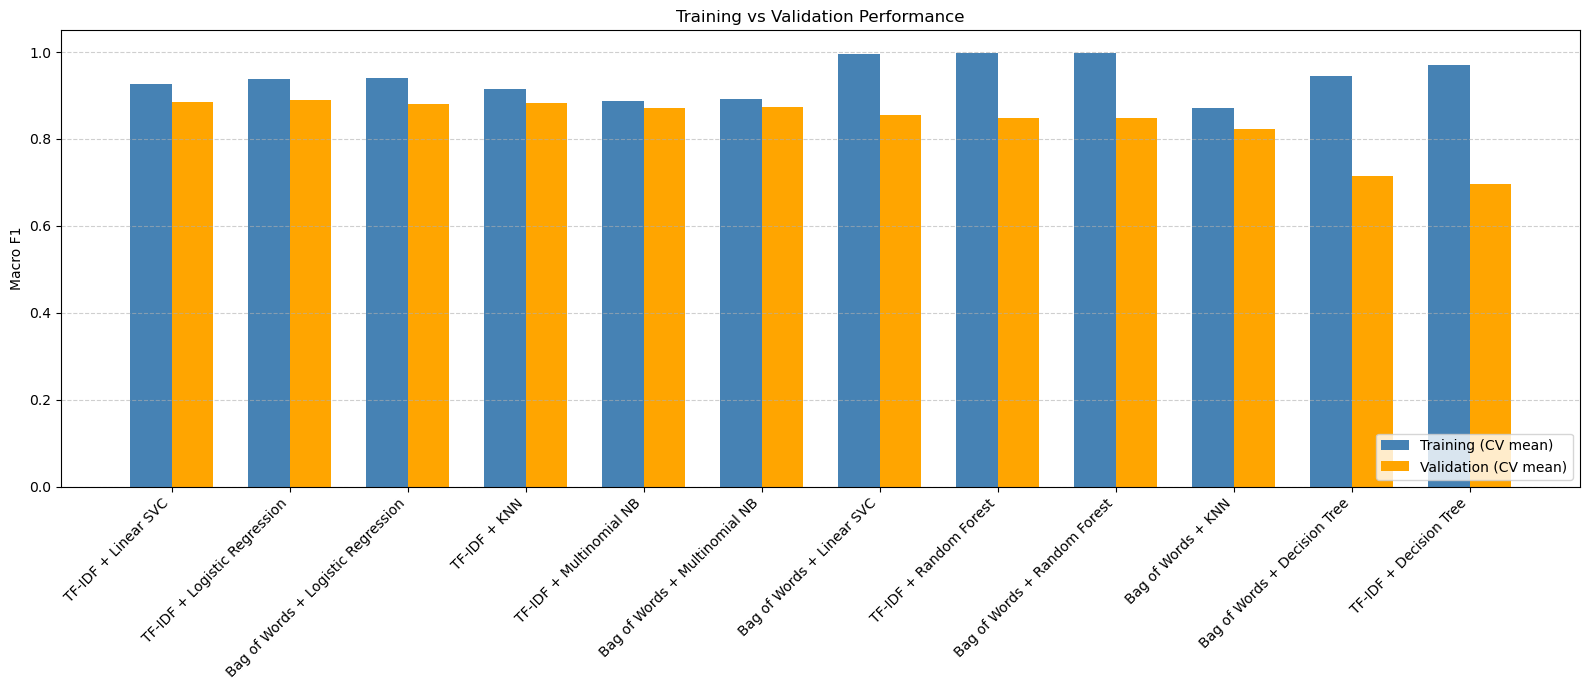

In [29]:
# Plot 2: Training vs Validation (overfitting check)
x = np.arange(len(results_df))
width = 0.35
plt.figure(figsize=(16, 7))
plt.bar(x - width/2, results_df["CV Train Score"], width, label="Training (CV mean)", color="steelblue")
plt.bar(x + width/2, results_df["CV Val Score"], width, label="Validation (CV mean)", color="orange")
plt.xticks(x, results_df.index, rotation=45, ha="right")
plt.ylabel("Macro F1")
plt.title("Training vs Validation Performance")
plt.ylim(0, 1.05)
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("outputs/training_vs_validation.png", dpi=600)
plt.show()

### 6.4 Plot: training vs validation learning curve for each model
The earlier plot only compares one final CV score per model. This block draws a **learning curve for every one of the 12 models**: macro F1 on the training folds and on the validation folds as the number of training samples grows (shaded bands show ±1 standard deviation across the 3 CV folds).

- Training and validation lines far apart means overfitting (typical for Decision Tree and Random Forest).
- Both lines low and close together means underfitting.
- A validation line still rising at the right edge means more data would help.

This refits each model several times, so it can take a few minutes (kNN is the slowest).

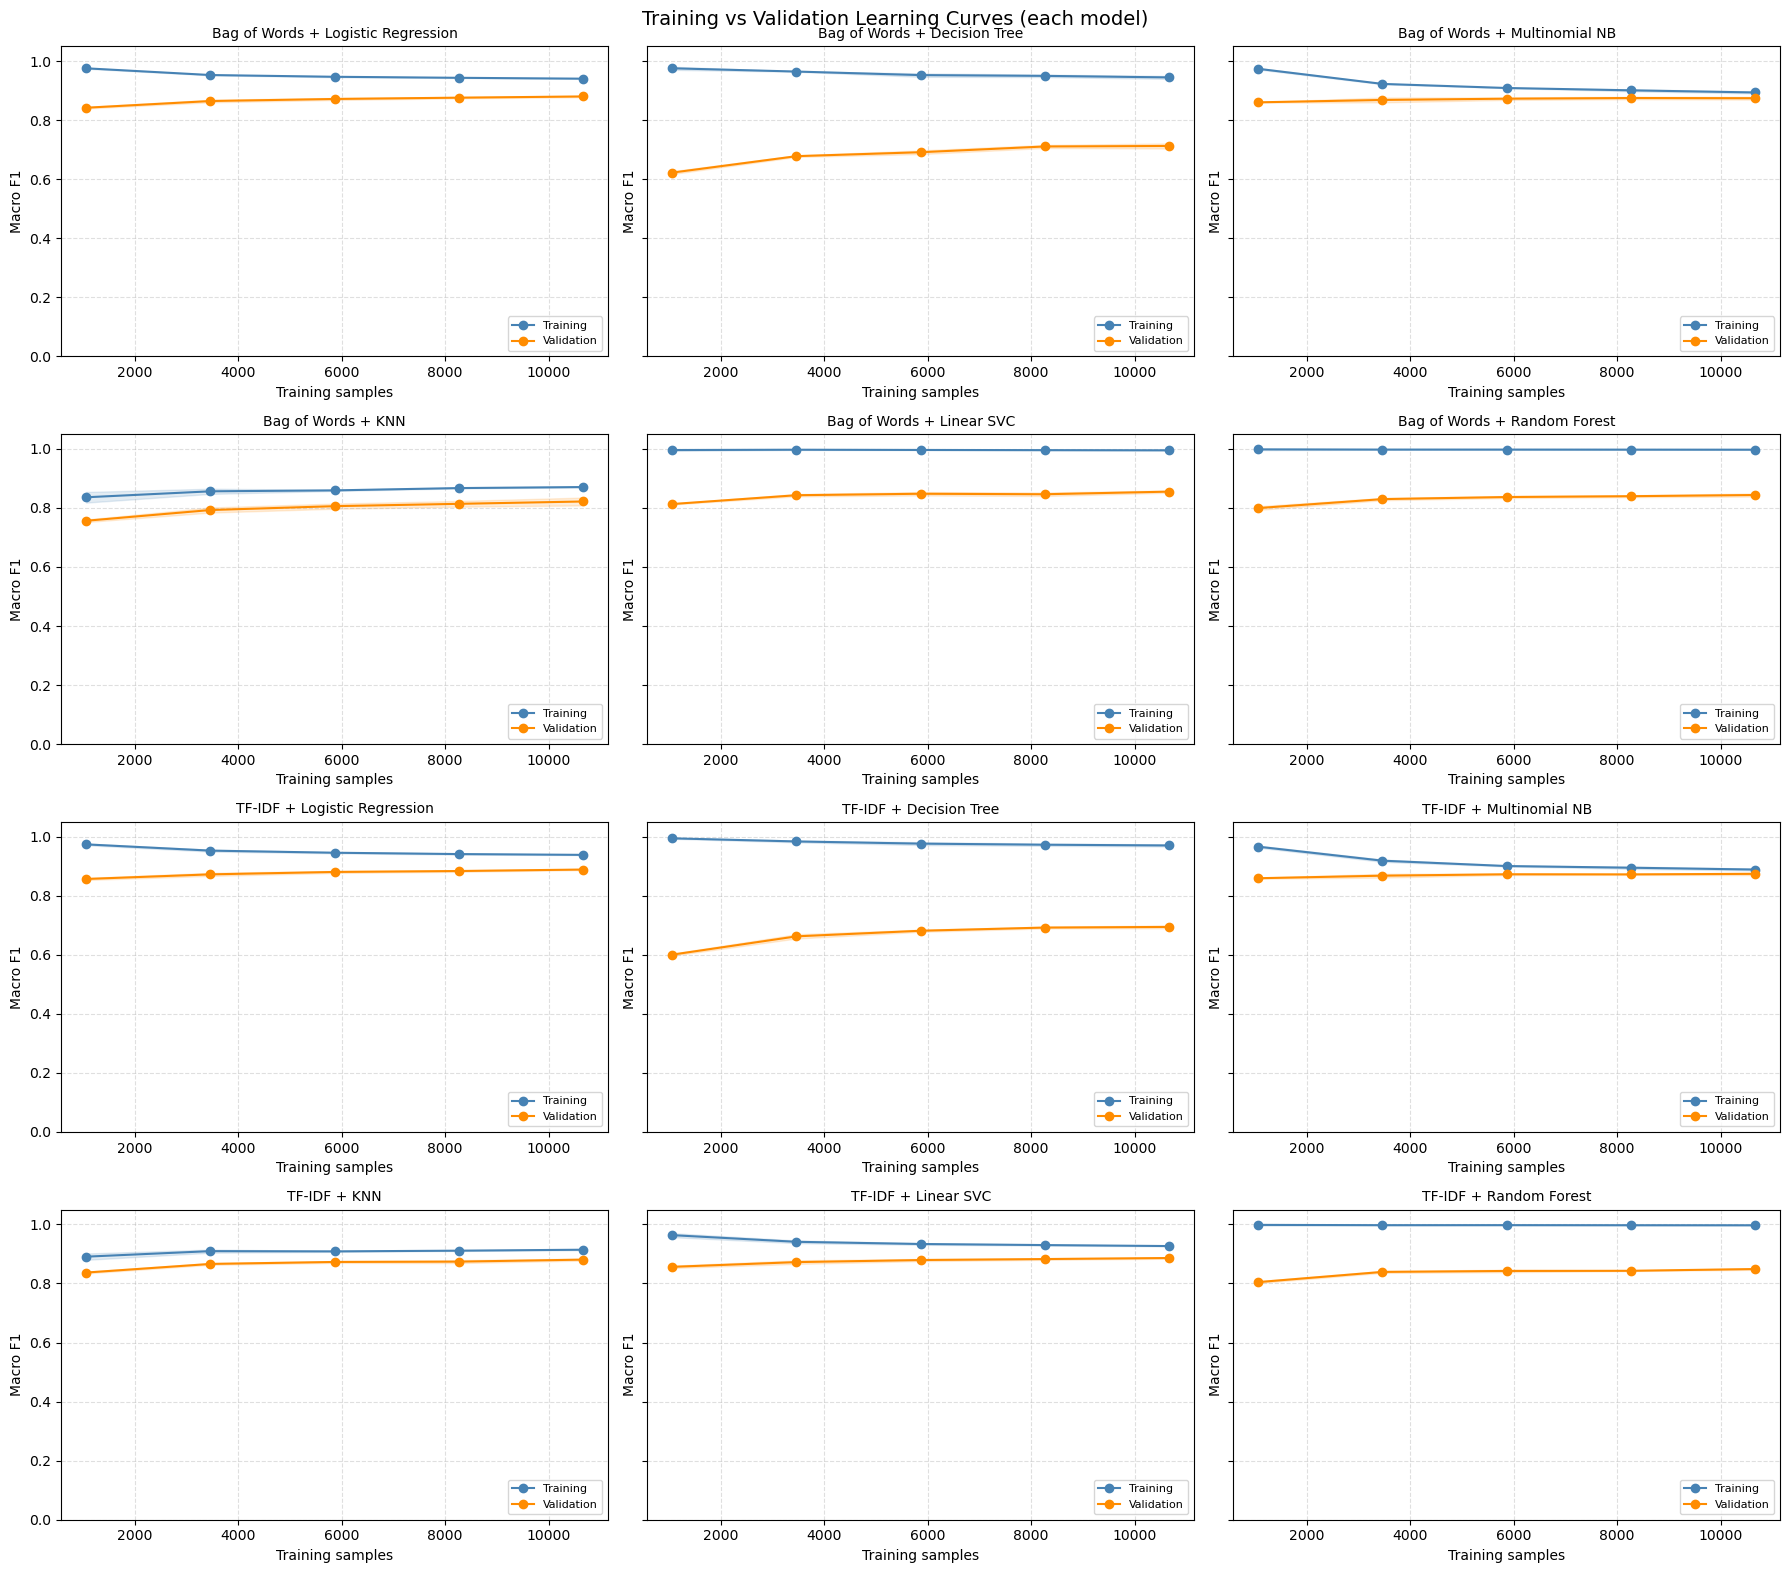

In [30]:
from sklearn.model_selection import learning_curve

train_sizes_frac = np.linspace(0.1, 1.0, 5)
curve_data = {}

n_models = len(best_models)
ncols = 3
nrows = int(np.ceil(n_models / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4 * nrows), sharey=True)
axes = np.atleast_1d(axes).ravel()

for ax, (combo_key, model) in zip(axes, best_models.items()):
    sizes, tr_scores, val_scores = learning_curve(
        model, X_train_raw, Y_train,
        train_sizes=train_sizes_frac,
        cv=3, scoring="f1_macro", n_jobs=-1, random_state=42,
    )
    tr_mean, tr_std = tr_scores.mean(axis=1), tr_scores.std(axis=1)
    val_mean, val_std = val_scores.mean(axis=1), val_scores.std(axis=1)
    curve_data[combo_key] = (sizes, tr_mean, val_mean)

    ax.plot(sizes, tr_mean, "o-", color="steelblue", label="Training")
    ax.fill_between(sizes, tr_mean - tr_std, tr_mean + tr_std, color="steelblue", alpha=0.15)
    ax.plot(sizes, val_mean, "o-", color="darkorange", label="Validation")
    ax.fill_between(sizes, val_mean - val_std, val_mean + val_std, color="darkorange", alpha=0.15)
    ax.set_title(combo_key, fontsize=10)
    ax.set_xlabel("Training samples")
    ax.set_ylabel("Macro F1")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.4, linestyle="--")
    ax.legend(loc="lower right", fontsize=8)

for ax in axes[n_models:]:
    ax.axis("off")

fig.suptitle("Training vs Validation Learning Curves (each model)", fontsize=14)
plt.tight_layout()
plt.savefig("outputs/learning_curves_all_models.png", dpi=300)
plt.show()

### 6. Plot: F-measure heatmap
Heatmap of test macro F-measure with models on one axis and vectorizers on the other, making it easy to see which feature type works better for each model.

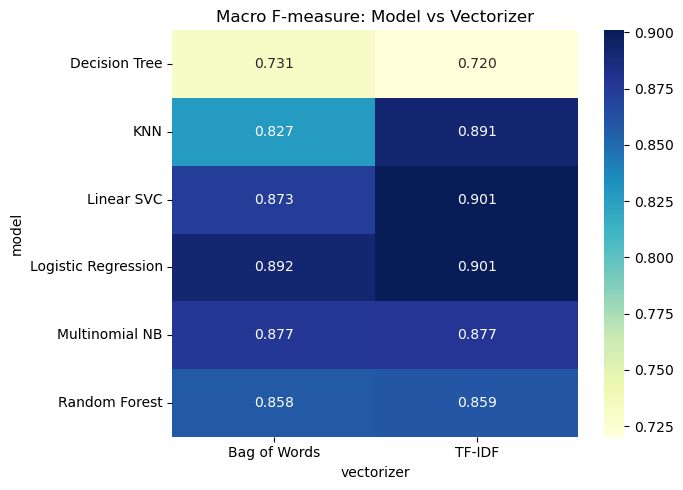

In [31]:
# Plot 3: Heatmap of F-measure, model x vectorizer
heat = results_df["F-measure"].copy()
heat_df = pd.DataFrame({
    "vectorizer": [k.split(" + ")[0] for k in heat.index],
    "model": [k.split(" + ")[1] for k in heat.index],
    "F-measure": heat.values,
}).pivot(index="model", columns="vectorizer", values="F-measure")

plt.figure(figsize=(7, 5))
sns.heatmap(heat_df, annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("Macro F-measure: Model vs Vectorizer")
plt.tight_layout()
plt.savefig("outputs/fmeasure_heatmap.png", dpi=600)
plt.show()

### 6.6 Plot: performance vs training cost
Scatter plot of grid-search fit time (log scale) against test F-measure, showing the accuracy-versus-cost trade-off.

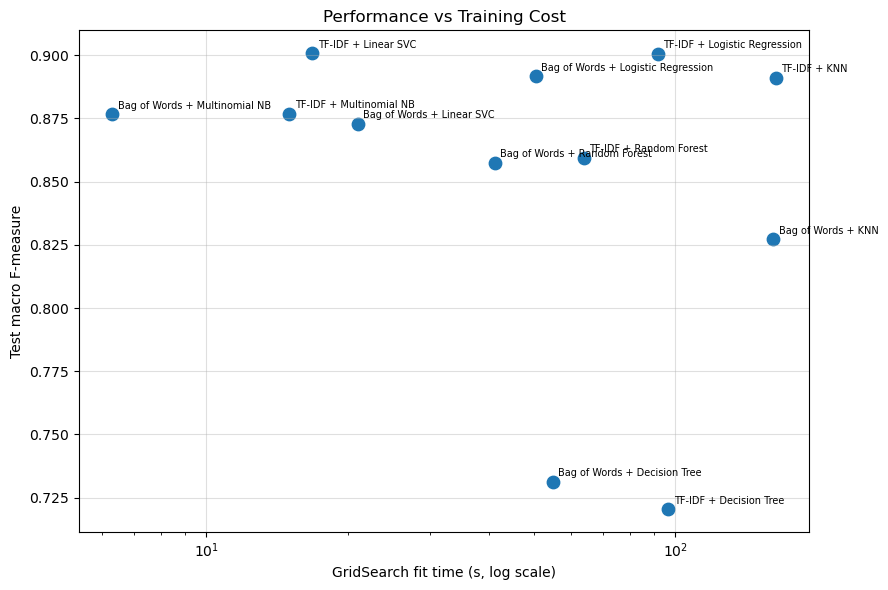

In [32]:
# ---- Plot 4: Accuracy vs training time trade-off ----
plt.figure(figsize=(9, 6))
plt.scatter(results_df["Fit Time (s)"].astype(float), results_df["F-measure"], s=80)
for name, row in results_df.iterrows():
    plt.annotate(name, (float(row["Fit Time (s)"]), row["F-measure"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
plt.xscale("log")
plt.xlabel("GridSearch fit time (s, log scale)")
plt.ylabel("Test macro F-measure")
plt.title("Performance vs Training Cost")
plt.grid(alpha=0.4)
plt.tight_layout()
plt.savefig("outputs/performance_vs_time.png", dpi=600)
plt.show()

# 7. Model Interpretation

### 7.1 Confusion matrices for every model
Saves a confusion matrix image (raw counts and row-normalised recall) for each of the 12 combinations into `outputs/`.

In [33]:
# Confusion matrices: raw + row-normalized for every combo
for combo_key, preds in preds_store.items():
    cm = confusion_matrix(Y_test, preds, labels=labels)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels, ax=axes[0])
    axes[0].set_title("Counts")
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
                xticklabels=labels, yticklabels=labels, ax=axes[1])
    axes[1].set_title("Row-normalized (recall per class)")
    for ax in axes:
        ax.set_xlabel("Predicted")
        ax.set_ylabel("True")
    fig.suptitle(f"Confusion Matrix: {combo_key}")
    plt.tight_layout()

    fname = f"outputs/cm_{combo_key.replace(' ', '_').replace('+', 'vs')}.png"
    plt.savefig(fname, dpi=300)
    plt.close()
print("Confusion matrix PNGs saved to outputs/")

Confusion matrix PNGs saved to outputs/


### 7.2 Training vs validation CV performance (with 90% line)
A second version of the overfitting plot, with a 90% reference line.

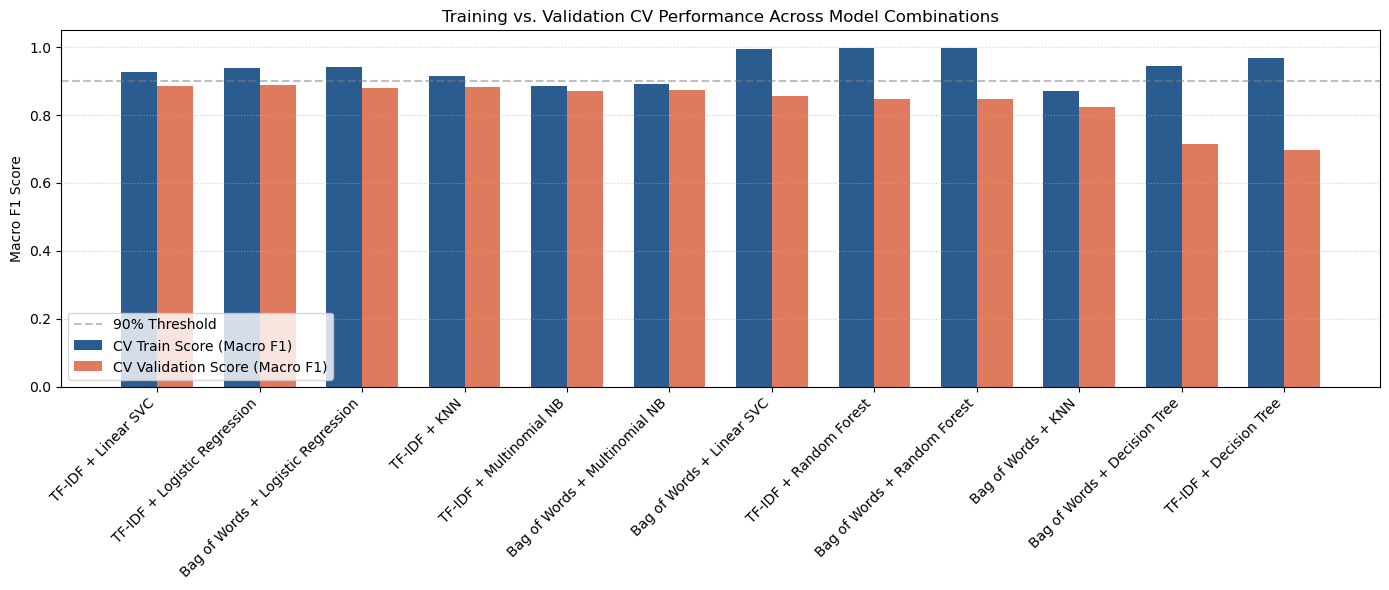

In [34]:
# Training vs. Validation Performance Plot 
plt.figure(figsize=(14, 6))
x = np.arange(len(results_df))
width = 0.35

# Side-by-side bars for Train vs Val F1 Scores
rects1 = plt.bar(x - width/2, results_df["CV Train Score"], width, label="CV Train Score (Macro F1)", color="#2b5c8f")
rects2 = plt.bar(x + width/2, results_df["CV Val Score"], width, label="CV Validation Score (Macro F1)", color="#e07a5f")

plt.ylabel("Macro F1 Score")
plt.title("Training vs. Validation CV Performance Across Model Combinations")
plt.xticks(x, results_df.index, rotation=45, ha="right")
plt.ylim(0, 1.05)
plt.axhline(0.9, color="gray", linestyle="--", alpha=0.5, label="90% Threshold")
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.legend(loc="lower left")
plt.tight_layout()

plt.savefig("outputs/train_vs_val_performance.png", dpi=300)
plt.show()

### 7.3 Best model: classification report and common mistakes
Prints the per-class precision, recall and F1 for the best model, then lists the class pairs it confuses most often.

In [35]:
# best model
best_key = results_df.index[0]
print(f"\nBest model: {best_key}")
print(classification_report(Y_test, preds_store[best_key], digits=3))

# Most confused class pairs for the best model
cm = confusion_matrix(Y_test, preds_store[best_key], labels=labels)
off_diag = [(labels[i], labels[j], cm[i, j])
            for i in range(len(labels)) for j in range(len(labels))
            if i != j and cm[i, j] > 0]
confused = pd.DataFrame(off_diag, columns=["True", "Predicted", "Count"]).sort_values("Count", ascending=False)
print("\nTop misclassification pairs:")
display(confused.head(10))


Best model: TF-IDF + Linear SVC
                precision    recall  f1-score   support

      Business      0.910     0.875     0.892      1334
       Science      0.931     0.926     0.928      1333
Social Science      0.864     0.902     0.883      1333

      accuracy                          0.901      4000
     macro avg      0.901     0.901     0.901      4000
  weighted avg      0.901     0.901     0.901      4000


Top misclassification pairs:


,True,Predicted,Count
1,Business,Social Science,122
4,Social Science,Business,84
3,Science,Social Science,67
5,Social Science,Science,47
0,Business,Science,45
2,Science,Business,32


### 7.4 Top discriminative terms per class (linear models)
Defines `plot_top_terms`, which reads the coefficients of a linear model and plots the words that most strongly indicate each class. It is then run for TF-IDF + Logistic Regression and TF-IDF + Linear SVC.

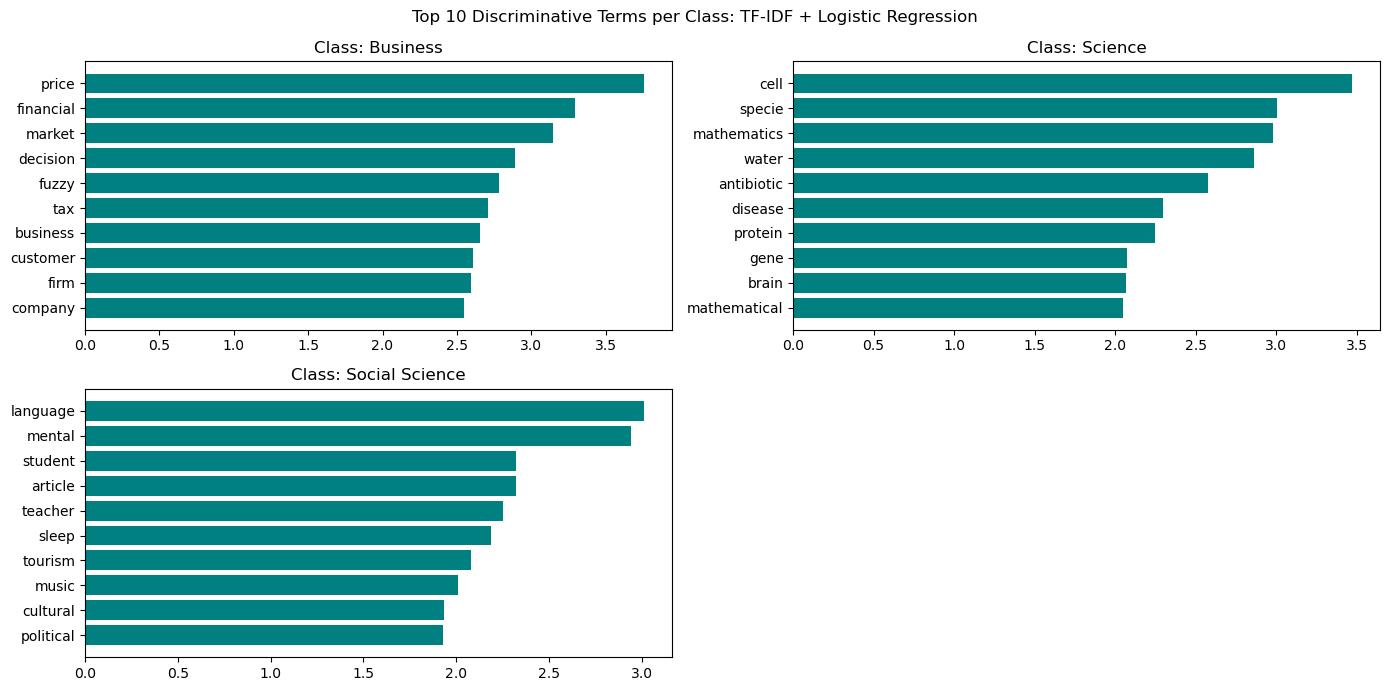

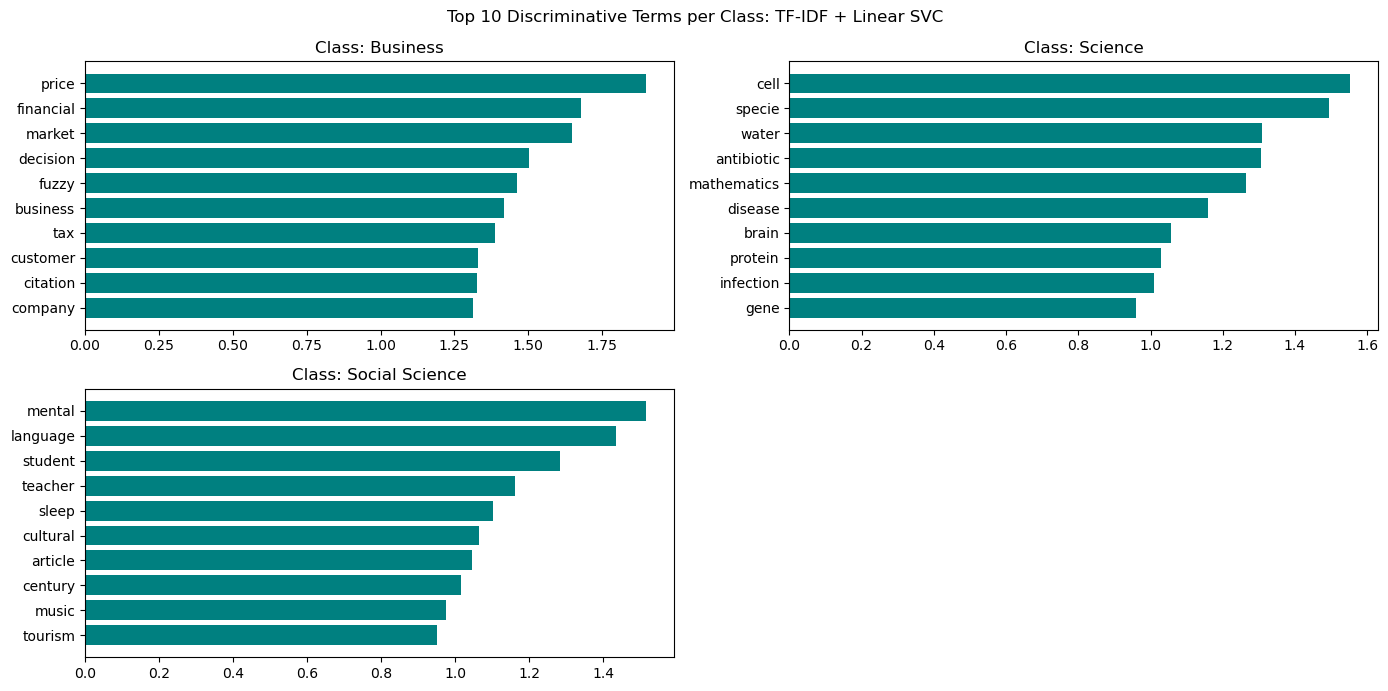

In [36]:
# Top terms per class (linear models: LR and Linear SVC)
def plot_top_terms(combo_key, top_n=10):
    model = best_models[combo_key]
    vec = model.named_steps["vectorizer"]
    clf = model.named_steps["classifier"]
    feature_names = np.array(vec.get_feature_names_out())
    coefs = clf.coef_

    # Binary problems give one coefficient row; mirror it for the other class
    if coefs.shape[0] == 1:
        coefs = np.vstack([-coefs[0], coefs[0]])

    n_classes = len(clf.classes_)
    ncols = 2 if n_classes > 1 else 1
    nrows = int(np.ceil(n_classes / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 3.5 * nrows))
    axes = np.atleast_1d(axes).ravel()

    for idx, cls in enumerate(clf.classes_):
        top = np.argsort(coefs[idx])[-top_n:]
        axes[idx].barh(feature_names[top], coefs[idx][top], color="teal")
        axes[idx].set_title(f"Class: {cls}")
    for ax in axes[n_classes:]:
        ax.axis("off")

    fig.suptitle(f"Top {top_n} Discriminative Terms per Class: {combo_key}")
    plt.tight_layout()
    plt.savefig(f"outputs/top_terms_{combo_key.replace(' ', '_').replace('+', 'vs')}.png", dpi=300)
    plt.show()

for key in ["TF-IDF + Logistic Regression", "TF-IDF + Linear SVC"]:
    plot_top_terms(key)

### 7.5 Random Forest feature importances
Shows the 20 words the Random Forest relies on most.

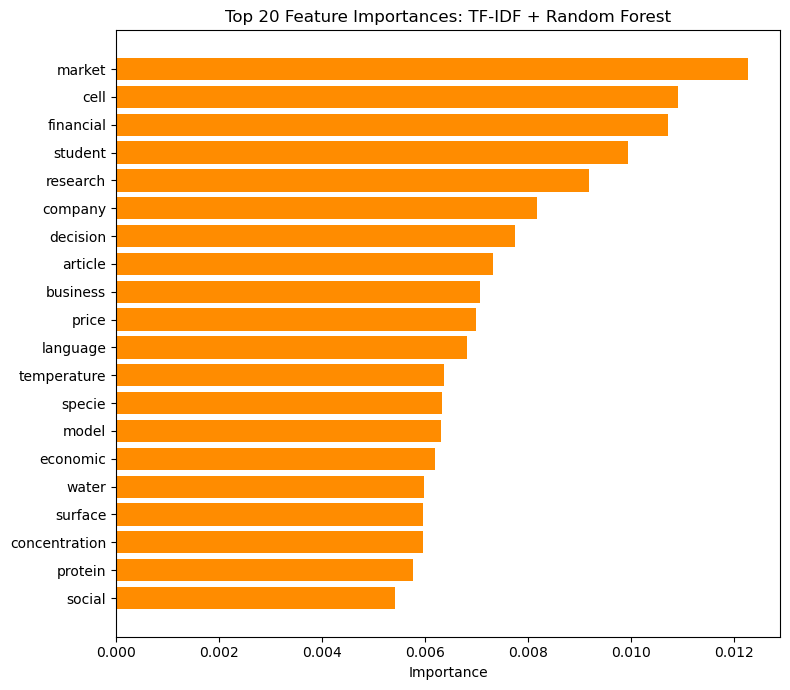

In [37]:
# Random Forest feature importances
rf_key = "TF-IDF + Random Forest"
rf_model = best_models[rf_key]
rf_names = np.array(rf_model.named_steps["vectorizer"].get_feature_names_out())
rf_imp = rf_model.named_steps["classifier"].feature_importances_
top_idx = np.argsort(rf_imp)[-20:]

plt.figure(figsize=(8, 7))
plt.barh(rf_names[top_idx], rf_imp[top_idx], color="darkorange")
plt.title("Top 20 Feature Importances: TF-IDF + Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("outputs/rf_feature_importances.png", dpi=300)
plt.show()

### 7.6 Decision Tree feature importances
Shows the 15 words the Decision Tree uses most for its splits.

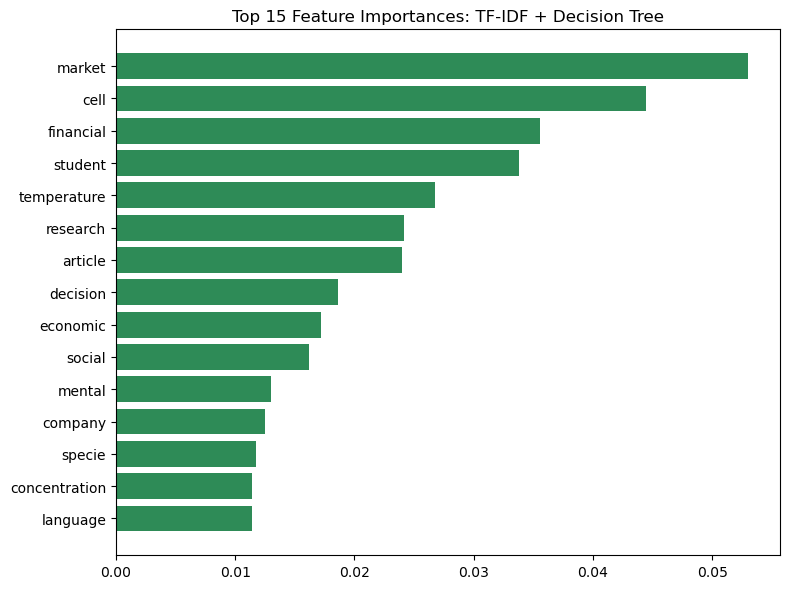

In [38]:
# Decision Tree top splitting terms
dt_key = "TF-IDF + Decision Tree"
dt_model = best_models[dt_key]
dt_names = np.array(dt_model.named_steps["vectorizer"].get_feature_names_out())
dt_imp = dt_model.named_steps["classifier"].feature_importances_
top_idx = np.argsort(dt_imp)[-15:]

plt.figure(figsize=(8, 6))
plt.barh(dt_names[top_idx], dt_imp[top_idx], color="seagreen")
plt.title("Top 15 Feature Importances: TF-IDF + Decision Tree")
plt.tight_layout()
plt.savefig("outputs/dt_feature_importances.png", dpi=300)
plt.show()

# 8. Save Trained Models

### 8.1 Export model pipelines
Saves every best pipeline (vectorizer + classifier together) with `joblib`, plus the overall best model as `best_model_pipeline.pkl`, so new abstracts can be classified without retraining.

In [39]:
import os
import joblib

# Create directory to store serialized models
models_dir = "outputs/saved_models"
os.makedirs(models_dir, exist_ok=True)

# Save each trained best pipeline from grid search
print("Saving best model pipelines...")
for combo_key, model_pipeline in best_models.items():
    # Clean filename string
    safe_filename = combo_key.replace(" ", "_").replace("+", "vs")
    filepath = os.path.join(models_dir, f"pipeline_{safe_filename}.pkl")
    
    # Save model pipeline (includes both Vectorizer and Classifier)
    joblib.dump(model_pipeline, filepath)
    print(f"Saved: {filepath}")

# save the single overall best model separately for easy access
best_overall_key = results_df.index[0]
best_overall_model = best_models[best_overall_key]
joblib.dump(best_overall_model, os.path.join(models_dir, "best_model.pkl"))
print(f"\nOverall best model ('{best_overall_key}') saved as 'best_model.pkl'")

Saving best model pipelines...
Saved: outputs/saved_models\pipeline_Bag_of_Words_vs_Logistic_Regression.pkl
Saved: outputs/saved_models\pipeline_Bag_of_Words_vs_Decision_Tree.pkl
Saved: outputs/saved_models\pipeline_Bag_of_Words_vs_Multinomial_NB.pkl
Saved: outputs/saved_models\pipeline_Bag_of_Words_vs_KNN.pkl
Saved: outputs/saved_models\pipeline_Bag_of_Words_vs_Linear_SVC.pkl
Saved: outputs/saved_models\pipeline_Bag_of_Words_vs_Random_Forest.pkl
Saved: outputs/saved_models\pipeline_TF-IDF_vs_Logistic_Regression.pkl
Saved: outputs/saved_models\pipeline_TF-IDF_vs_Decision_Tree.pkl
Saved: outputs/saved_models\pipeline_TF-IDF_vs_Multinomial_NB.pkl
Saved: outputs/saved_models\pipeline_TF-IDF_vs_KNN.pkl
Saved: outputs/saved_models\pipeline_TF-IDF_vs_Linear_SVC.pkl
Saved: outputs/saved_models\pipeline_TF-IDF_vs_Random_Forest.pkl

Overall best model ('TF-IDF + Linear SVC') saved as 'best_model.pkl'


# Abstract Text Classification

Classifies research-paper abstracts into **Science**, **Business** and **Social Science** using
classical machine-learning models (Logistic Regression, Decision Tree, Multinomial Naive Bayes, kNN,
Linear SVC, Random Forest) with **Bag-of-Words** and **TF-IDF** features.

Everything lives in one notebook: `Project1_26566019_structured.ipynb`

## Pipeline

1. Dataset collection from the OpenAlex API
2. Loading and cleaning
3. Text preprocessing (NLTK)
4. Stratified train/test split
5. Model training with `GridSearchCV`
6. Evaluation and comparison
7. Model interpretation
8. Saving trained models

## 1. Dataset

Built from the [OpenAlex API](https://api.openalex.org/works) (`primary_topic.field`, English journal
articles with abstracts). Abstracts are sampled per research field and per year so the data is
balanced across classes, fields and time.

| Setting | Value |
|---|---|
| Total abstracts | 20,000 |
| Publication years | 2016 - 2025 (about 2,000 per year) |
| Abstract length | 50 - 500 words (mean about 182 - 194 per class) |
| Minimum topic confidence | 0.9 |
| Random seed | 42 |

| Class | Abstracts | OpenAlex fields |
|---|---:|---|
| Science | 6,667 | Agricultural & Biological Sciences, Biochemistry/Genetics/Molecular Biology, Chemistry, Earth & Planetary Sciences, Physics & Astronomy, Environmental Science, Immunology & Microbiology, Materials Science, Mathematics, Neuroscience |
| Business | 6,667 | Business/Management/Accounting, Economics/Econometrics/Finance, Decision Sciences |
| Social Science | 6,666 | Social Sciences, Psychology, Arts & Humanities |

Collection details:
- OpenAlex returns abstracts as an inverted index (word -> positions); `reconstruct_abstract` rebuilds the text and `clean_abstract` strips HTML, a leading "Abstract" label and copyright boilerplate.
- `fetch_batch` retries with exponential backoff on HTTP 429 / 5xx errors.
- `try_add` filters on topic score, duplicate IDs, duplicate abstracts and word count.
- A main pass collects an even quota per (field, year), then a top-up pass fills any shortfall.
- Output is saved to `abstracts.csv` (columns: title, Abstract, label, field, subfield, topic, topic_score, year, journal, doi, openalex_id, word_count).

## 2. Cleaning

- Keep only `Abstract` and `label`; drop empty abstracts.
- Duplicate abstracts: 0 found, final shape (20000, 2), classes unchanged.

## 3. Text preprocessing

- Unicode normalised to ASCII; emails and URLs removed
- Contractions expanded (`can't` -> `cannot`)
- Tokenised and POS-tagged, then lower-cased
- Stopwords removed, but **negation words are kept** (`no`, `not`, `never`, `cannot`, ...)
- Hyphenated tokens split, single letters dropped (numbers kept)
- POS-aware WordNet lemmatisation (cached with `lru_cache`)
- Result stored in the `Cleaned_Abstract` column

## 4. Train/test split

80/20 stratified split: **16,000 train / 4,000 test**, 3 classes, `random_state=42`.

## 5. Models and hyperparameter search

3-fold `GridSearchCV`, scored on macro F1, for 6 classifiers x 2 vectorizers = **12 pipelines**.

| Classifier | Grid |
|---|---|
| Logistic Regression | C: 0.01, 0.1, 1, 10, 50 |
| Decision Tree | max_depth: 5, 10, 20, 30, 50; min_samples_split: 2, 5, 10 |
| Multinomial NB | alpha: 0.1, 0.5, 1.0 |
| kNN | n_neighbors: 3, 5, 7; metric: cosine, euclidean |
| Linear SVC | C: 0.1, 1, 10 |
| Random Forest | n_estimators: 50, 100; max_depth: None, 30, 50 |

| Vectorizer | Settings |
|---|---|
| Bag of Words | `CountVectorizer(max_features=5000)` |
| TF-IDF | `TfidfVectorizer(ngram_range=(1, 2), max_features=5000, sublinear_tf=True, min_df=3)` |

## 6. Results (held-out test set, sorted by F-measure)

| Rank | Model | Test Acc | Precision | Recall | F-measure | CV Train F1 | CV Val F1 | Overfit Gap | Fit Time (s) |
|---:|---|---:|---:|---:|---:|---:|---:|---:|---:|


**Observations**
- **Best model: TF-IDF + Linear SVC** with 0.9008 accuracy and 0.9009 macro F-measure. It is also one of the fastest to tune (16.8 s).
- TF-IDF + Logistic Regression is practically tied (0.9006 F-measure) but about 5x slower to tune.
- TF-IDF matches or beats Bag of Words for most models; kNN and Linear SVC gain the most.
- Decision Tree and Random Forest overfit heavily (CV train F1 up to 0.997 vs validation about 0.70 - 0.85; gap up to 0.27).
- Naive Bayes has the smallest overfit gap (0.015 - 0.020) and trains fastest, but is about 2.4 points of F-measure behind the best.
- kNN is the slowest to tune (about 160 s).

### Test-set performance

![Test-set performance, all combinations](outputs/metrics_comparison.png)

### Training vs validation (overfitting check)

![Training vs validation](outputs/training_vs_validation.png)

### Training vs validation with 90% reference line

![Training vs validation with 90% line](outputs/train_vs_val_performance.png)

### Macro F-measure: model vs vectorizer

![F-measure heatmap](outputs/fmeasure_heatmap.png)

### Performance vs training cost

![Performance vs training time](outputs/performance_vs_time.png)

### Learning curves for every model

![Learning curves, all models](outputs/learning_curves_all_models.png)

## 7. Interpretation (code included)

Section 7 of the notebook produces the following files in `outputs/`:
- Confusion matrices (counts and row-normalised) for all 12 models
- Training vs validation CV plot with a 90% reference line
- Classification report and top misclassified class pairs for the best model
- Top discriminative terms per class (TF-IDF + Logistic Regression and TF-IDF + Linear SVC)
- Random Forest (top 20) and Decision Tree (top 15) feature importances

### Confusion matrix of the best model (TF-IDF + Linear SVC)

![Confusion matrix TF-IDF + Linear SVC](outputs/cm_TF-IDF_vs_Linear_SVC.png)

<details>
<summary><b>Confusion matrices for all 12 models</b> (counts and row-normalised recall)</summary>

#### Bag of Words

**Bag of Words + Logistic Regression**

![Confusion matrix Bag of Words + Logistic Regression](outputs/cm_Bag_of_Words_vs_Logistic_Regression.png)

**Bag of Words + Decision Tree**

![Confusion matrix Bag of Words + Decision Tree](outputs/cm_Bag_of_Words_vs_Decision_Tree.png)

**Bag of Words + Multinomial NB**

![Confusion matrix Bag of Words + Multinomial NB](outputs/cm_Bag_of_Words_vs_Multinomial_NB.png)

**Bag of Words + KNN**

![Confusion matrix Bag of Words + KNN](outputs/cm_Bag_of_Words_vs_KNN.png)

**Bag of Words + Linear SVC**

![Confusion matrix Bag of Words + Linear SVC](outputs/cm_Bag_of_Words_vs_Linear_SVC.png)

**Bag of Words + Random Forest**

![Confusion matrix Bag of Words + Random Forest](outputs/cm_Bag_of_Words_vs_Random_Forest.png)

#### TF-IDF

**TF-IDF + Logistic Regression**

![Confusion matrix TF-IDF + Logistic Regression](outputs/cm_TF-IDF_vs_Logistic_Regression.png)

**TF-IDF + Decision Tree**

![Confusion matrix TF-IDF + Decision Tree](outputs/cm_TF-IDF_vs_Decision_Tree.png)

**TF-IDF + Multinomial NB**

![Confusion matrix TF-IDF + Multinomial NB](outputs/cm_TF-IDF_vs_Multinomial_NB.png)

**TF-IDF + KNN**

![Confusion matrix TF-IDF + KNN](outputs/cm_TF-IDF_vs_KNN.png)

**TF-IDF + Linear SVC**

![Confusion matrix TF-IDF + Linear SVC](outputs/cm_TF-IDF_vs_Linear_SVC.png)

**TF-IDF + Random Forest**

![Confusion matrix TF-IDF + Random Forest](outputs/cm_TF-IDF_vs_Random_Forest.png)

</details>

### Top discriminative terms: TF-IDF + Logistic Regression

![Top terms TF-IDF + Logistic Regression](outputs/top_terms_TF-IDF_vs_Logistic_Regression.png)

### Top discriminative terms: TF-IDF + Linear SVC

![Top terms TF-IDF + Linear SVC](outputs/top_terms_TF-IDF_vs_Linear_SVC.png)

### Random Forest feature importances

![Random Forest feature importances](outputs/rf_feature_importances.png)

### Decision Tree feature importances

![Decision Tree feature importances](outputs/dt_feature_importances.png)

Note: the saved notebook only contains outputs up to the training-vs-validation plot (section 6.3).
The learning curves, heatmap, cost plot and all of sections 7 - 8 have no saved outputs, so re-run
the notebook to generate them.

## 8. Saved models

Each best pipeline (vectorizer + classifier) is saved with `joblib` to `outputs/saved_models/` as
`pipeline_<combo>.pkl`, plus the overall best as `best_model.pkl`.

Files in `outputs/saved_models/`:

- `best_model.pkl`
- `pipeline_Bag_of_Words_vs_Decision_Tree.pkl`
- `pipeline_Bag_of_Words_vs_KNN.pkl`
- `pipeline_Bag_of_Words_vs_Linear_SVC.pkl`
- `pipeline_Bag_of_Words_vs_Logistic_Regression.pkl`
- `pipeline_Bag_of_Words_vs_Multinomial_NB.pkl`
- `pipeline_Bag_of_Words_vs_Random_Forest.pkl`
- `pipeline_TF-IDF_vs_Decision_Tree.pkl`
- `pipeline_TF-IDF_vs_KNN.pkl`
- `pipeline_TF-IDF_vs_Linear_SVC.pkl`
- `pipeline_TF-IDF_vs_Logistic_Regression.pkl`
- `pipeline_TF-IDF_vs_Multinomial_NB.pkl`
- `pipeline_TF-IDF_vs_Random_Forest.pkl`

```python
import joblib
model = joblib.load("outputs/saved_models/best_model.pkl")
print(model.predict(["We study the effect of interest-rate shocks on firm investment ..."]))
```

## 9. Predict on new abstracts with `run.py`

`run.py` is a small desktop app (Tkinter) that loads the saved best pipeline and classifies new
abstracts. It looks for the model at `outputs/saved_models/best_model_pipeline.pkl`, then
`outputs/saved_models/best_model.pkl`.

```
python run.py
```

**Tab 1 - Single Abstract**
- Paste an abstract, or click **Upload .txt...** to load a text file into the box.
- Click **Classify Abstract** to see the predicted class. Models with probabilities (e.g. Logistic
  Regression) show percentages; Linear SVC shows decision scores instead.

**Tab 2 - Batch Upload (CSV / TXT)**
- Choose a `.csv` or `.txt` file with **Browse...**.
- **CSV:** type the name of the column that holds the abstracts (default `Abstract`, not case-sensitive).
- **TXT:** pick how the file is split into abstracts: one per line, blank-line-separated blocks, or the whole file as one.
- Click **Run Predictions**. Results are saved to `outputs/predictions_<input file name>.csv` with a
  `Predicted_Category` column (and `Confidence` when the model supports probabilities). Blank rows are skipped.

_Screenshot not found: `output/run_py_batch_prediction.png`._

_Batch tab after running predictions on a CSV of about 20,000 abstracts._

**Notes**
- The models were trained on preprocessed text (lemmatised, stopwords removed), so `run.py` applies
  the same NLTK preprocessing to new text. Install NLTK (`pip install nltk`) and let it download its
  resources on first launch. If NLTK is missing, the window shows "NLTK not available, simplified
  cleaning was used" and predictions can be less accurate.
- Running a large file takes a while; a progress bar is shown and the window stays responsive.

## Output files

```
Project1_26566019_structured.ipynb
run.py                           (prediction app)
abstracts.csv
screenshots/
  run_py_batch_prediction.png
outputs/
  predictions_<input>.csv        (written by run.py)
  model_comparison_results.csv
  metrics_comparison.png
  training_vs_validation.png
  learning_curves_all_models.png
  fmeasure_heatmap.png
  performance_vs_time.png
  cm_<combo>.png                 (12 files)
  train_vs_val_performance.png
  top_terms_<combo>.png
  rf_feature_importances.png
  dt_feature_importances.png
  saved_models/
    pipeline_<combo>.pkl         (12 files)
    best_model.pkl
```

## Requirements

Python 3.9+ and:

```
requests pandas numpy matplotlib seaborn scikit-learn nltk tqdm joblib
```

NLTK resources downloaded by the notebook: `punkt`, `punkt_tab`, `stopwords`, `wordnet`,
`averaged_perceptron_tagger`, `averaged_perceptron_tagger_eng`.

## How to run

1. Install the requirements above.
2. Open `Project1_26566019_structured.ipynb` in Jupyter or Colab and run all cells in order.
3. Section 1 needs internet access (OpenAlex API). Set `MAILTO` to your own email for the API polite pool.
   To skip collection, place an existing `abstracts.csv` next to the notebook and start from section 2.
4. Section 5.4 (GridSearchCV) is the slowest step; section 6.4 (learning curves) also takes several minutes.

## Known notes

- Section 2.1 has leftover unused lines (`Dataset = ''`, commented `os.listdir`).
- Some abstracts are non-English (e.g. Turkish and Greek titles appear in the sample) despite the `language:en` filter; they lose characters during the ASCII normalisation step.
- Rankings are based on a single 80/20 split, so differences of a few tenths of a point (e.g. SVC vs Logistic Regression) are not conclusive.
